# Graph WaveNet vs GC-LSTM Demo

Notebook ini digunakan untuk membandingkan perilaku prediksi:

- Hybrid Graph WaveNet
- GC-LSTM Fair

Setup:
- dataset: Final64
- seed: 42
- input: 12 jam historical `current_speed`
- output: t+1, t+3, t+6

Demo mencakup:
- historical input;
- nilai aktual;
- prediksi Hybrid GWN;
- prediksi GC-LSTM;
- absolute error per horizon;
- computation cost;
- contoh normal case dan high-error case.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

CURRENT_DIR = Path.cwd().resolve()


def find_project_root(start_path: Path):
    candidates = [start_path] + list(start_path.parents)

    for path in candidates:
        if (path / "data" / "final_64").exists() and (path / "outputs" / "final_64").exists():
            return path

    raise FileNotFoundError("Project root tidak ditemukan.")


ROOT = find_project_root(CURRENT_DIR)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)
print("TensorFlow:", tf.__version__)

Project root: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent
TensorFlow: 2.21.0


## Load Final64 Test Data dan Scaler

Test set Final64 digunakan untuk membandingkan prediksi kedua model pada sample dan corridor yang sama.

In [2]:
DATA_DIR = ROOT / "data" / "final_64"

TEST_PATH = DATA_DIR / "stgnn_test.npz"

SCALER_PATH = DATA_DIR / "stgnn_scaler.npz"

test_data = np.load(TEST_PATH, allow_pickle=True)

scaler_data = np.load(SCALER_PATH, allow_pickle=True)

X_test = test_data["X"].astype(np.float32)
y_test = test_data["y"].astype(np.float32)
mask_test = test_data["mask"].astype(np.float32)

SCALER_MEAN = float(scaler_data["mean"][0])

SCALER_SCALE = float(scaler_data["scale"][0])


def inverse_scale(x):
    return x * SCALER_SCALE + SCALER_MEAN


print("X_test :", X_test.shape)
print("y_test :", y_test.shape)
print("mask   :", mask_test.shape)
print("Mean   :", SCALER_MEAN)
print("Scale  :", SCALER_SCALE)

X_test : (93, 12, 64, 1)
y_test : (93, 3, 64)
mask   : (93, 3, 64)
Mean   : 30.50661914460285
Scale  : 11.331123867533398


## Load Hybrid Graph WaveNet dan GC-LSTM Fair

Kedua model menggunakan weights seed 42 yang sudah dilatih sebelumnya.

- Hybrid Graph WaveNet di-load dari model loader.
- GC-LSTM Fair dibangun ulang dengan arsitektur yang sama seperti notebook baseline, kemudian weights fair version dimuat.

In [3]:
from streamlit_app.model_loader import load_graphwavenet_model

# ============================================================
# LOAD HYBRID GWN
# ============================================================

hybrid_model = load_graphwavenet_model("hybrid")

print("Hybrid GWN params:", hybrid_model.count_params())

Hybrid GWN params: 293955


## Rebuild GC-LSTM Fair Architecture

GC-LSTM menggunakan:
- fixed normalized adjacency;
- graph propagation;
- LSTM untuk temporal modeling;
- output t+1, t+3, dan t+6.

In [5]:
from tensorflow.keras import layers, Model

GRAPH_PATH = ROOT / "outputs" / "final_64" / "fixed_graph" / "fixed_graph_64.npz"

graph_data = np.load(GRAPH_PATH, allow_pickle=True)

A = graph_data["directed_knn_adjacency"].astype(np.float32)

I = np.eye(A.shape[0], dtype=np.float32)

A_hat = A + I

row_sum = A_hat.sum(axis=1, keepdims=True)

A_norm = A_hat / np.maximum(row_sum, 1e-8)

NUM_NODES = 64
INPUT_STEPS = 12
NUM_HORIZONS = 3

GC_UNITS = 32
LSTM_UNITS = 64
DROPOUT = 0.3


class GraphPropagation(layers.Layer):
    def __init__(self, adjacency, units, **kwargs):
        super().__init__(**kwargs)

        self.adjacency = tf.constant(adjacency, dtype=tf.float32)

        self.proj = layers.Dense(units, activation="relu")

    def call(self, x):
        x = tf.einsum("ij,btjf->btif", self.adjacency, x)

        return self.proj(x)


def build_gclstm():
    inputs = layers.Input(shape=(INPUT_STEPS, NUM_NODES, 1))

    x = GraphPropagation(A_norm, GC_UNITS)(inputs)

    x = layers.Reshape((INPUT_STEPS, NUM_NODES * GC_UNITS))(x)

    x = layers.LSTM(LSTM_UNITS)(x)

    x = layers.Dropout(DROPOUT)(x)

    x = layers.Dense(NUM_HORIZONS * NUM_NODES)(x)

    outputs = layers.Reshape((NUM_HORIZONS, NUM_NODES))(x)

    return Model(inputs, outputs, name="GC_LSTM_Fair")


gclstm_fair = build_gclstm()

# build model
_ = gclstm_fair(X_test[:1], training=False)

GCLSTM_FAIR_WEIGHTS = (
    ROOT / "outputs" / "final_64" / "gclstm_baseline" / "gclstm_fair_seed42.weights.h5"
)

print("GC-LSTM fair weights exists:", GCLSTM_FAIR_WEIGHTS.exists())

gclstm_fair.load_weights(GCLSTM_FAIR_WEIGHTS)

print("GC-LSTM Fair params:", gclstm_fair.count_params())

GC-LSTM fair weights exists: True
GC-LSTM Fair params: 553472


## Generate Predictions from Both Models

Hybrid Graph WaveNet dan GC-LSTM Fair digunakan untuk menghasilkan prediksi pada seluruh test set Final64.

Prediksi kemudian dibandingkan terhadap nilai aktual pada horizon:
- t+1
- t+3
- t+6

In [6]:
# ============================================================
# GENERATE PREDICTIONS
# ============================================================

hybrid_pred_std = hybrid_model(X_test, training=False).numpy()

gclstm_pred_std = gclstm_fair(X_test, training=False).numpy()

# inverse scale
hybrid_pred = inverse_scale(hybrid_pred_std)

gclstm_pred = inverse_scale(gclstm_pred_std)

y_true_real = inverse_scale(y_test)

print("Hybrid pred :", hybrid_pred.shape)
print("GC-LSTM pred:", gclstm_pred.shape)
print("Actual      :", y_true_real.shape)

print("\nFinite check:")
print("Hybrid :", np.isfinite(hybrid_pred).all())
print("GC-LSTM:", np.isfinite(gclstm_pred).all())
print("Actual :", np.isfinite(y_true_real).all())

Hybrid pred : (93, 3, 64)
GC-LSTM pred: (93, 3, 64)
Actual      : (93, 3, 64)

Finite check:
Hybrid : True
GC-LSTM: True
Actual : True


Hybrid pred : (93, 3, 64)
GC-LSTM pred: (93, 3, 64)
Actual      : (93, 3, 64)

Hybrid : True
GC-LSTM: True
Actual : True

In [7]:
# ============================================================
# CALCULATE SAMPLE-LEVEL ERRORS
# ============================================================

rows = []

for sample_idx in range(len(X_test)):
    for node_idx in range(NUM_NODES):
        valid = mask_test[sample_idx, :, node_idx] == 1

        if not np.any(valid):
            continue

        actual = y_true_real[sample_idx, :, node_idx][valid]

        hybrid = hybrid_pred[sample_idx, :, node_idx][valid]

        gclstm = gclstm_pred[sample_idx, :, node_idx][valid]

        hybrid_mae = np.mean(np.abs(actual - hybrid))

        gclstm_mae = np.mean(np.abs(actual - gclstm))

        rows.append(
            {
                "sample_idx": sample_idx,
                "node_idx": node_idx,
                "valid_horizons": int(valid.sum()),
                "hybrid_mae": float(hybrid_mae),
                "gclstm_mae": float(gclstm_mae),
                "difference": float(gclstm_mae - hybrid_mae),
            }
        )

case_df = pd.DataFrame(rows)

print("Total valid sample-node cases:", len(case_df))

display(case_df.head())

Total valid sample-node cases: 5952


,sample_idx,node_idx,valid_horizons,hybrid_mae,gclstm_mae,difference
0,0,0,1,0.902531,2.082188,1.179657
1,0,1,1,9.179417,0.741898,-8.437519
2,0,2,1,1.591042,0.241871,-1.349171
3,0,3,1,1.443220,0.525848,-0.917372
4,0,4,1,1.998434,0.210155,-1.788279


## Select Representative Demo Cases

Kasus demo dipilih berdasarkan error rata-rata per sample-node:

- Normal case: kedua model memiliki error relatif kecil.
- Hybrid better case: error Hybrid lebih kecil dibanding GC-LSTM.
- GC-LSTM better case: error GC-LSTM lebih kecil dibanding Hybrid.
- High-error case: kedua model memiliki error besar.

Untuk visualisasi yang lebih informatif, diprioritaskan sample-node dengan minimal 2 horizon valid.

In [8]:
# ============================================================
# SELECT REPRESENTATIVE CASES
# ============================================================

demo_pool = case_df[case_df["valid_horizons"] >= 2].copy()

print("Cases with >= 2 valid horizons:", len(demo_pool))

# ------------------------------------------------------------
# Normal case:
# kedua model error kecil
# ------------------------------------------------------------

demo_pool["mean_error_both"] = (demo_pool["hybrid_mae"] + demo_pool["gclstm_mae"]) / 2

normal_case = demo_pool.sort_values("mean_error_both", ascending=True).iloc[0]

# ------------------------------------------------------------
# Hybrid better:
# difference = gclstm_mae - hybrid_mae
# semakin besar positif -> Hybrid lebih baik
# ------------------------------------------------------------

hybrid_better_case = demo_pool.sort_values("difference", ascending=False).iloc[0]

# ------------------------------------------------------------
# GC-LSTM better:
# semakin negatif -> GC-LSTM lebih baik
# ------------------------------------------------------------

gclstm_better_case = demo_pool.sort_values("difference", ascending=True).iloc[0]

# ------------------------------------------------------------
# High-error:
# kedua model sama-sama error besar
# ------------------------------------------------------------

demo_pool["min_model_error"] = demo_pool[["hybrid_mae", "gclstm_mae"]].min(axis=1)

high_error_case = demo_pool.sort_values("min_model_error", ascending=False).iloc[0]

selected_cases = pd.DataFrame(
    [
        {"case": "Normal", **normal_case.to_dict()},
        {"case": "Hybrid Better", **hybrid_better_case.to_dict()},
        {"case": "GC-LSTM Better", **gclstm_better_case.to_dict()},
        {"case": "High Error", **high_error_case.to_dict()},
    ]
)

display(
    selected_cases[
        [
            "case",
            "sample_idx",
            "node_idx",
            "valid_horizons",
            "hybrid_mae",
            "gclstm_mae",
            "difference",
        ]
    ]
)

Cases with >= 2 valid horizons: 2944


,case,sample_idx,node_idx,valid_horizons,hybrid_mae,gclstm_mae,difference
0,Normal,35.0,4.0,2.0,0.031555,0.101852,0.070297
1,Hybrid Better,11.0,13.0,2.0,2.332834,12.286169,9.953335
2,GC-LSTM Better,85.0,13.0,2.0,25.410378,3.620518,-21.789860
3,High Error,39.0,61.0,2.0,27.038925,22.145992,-4.892933


## Visualize Representative Cases

Setiap kasus menampilkan:

- 12 jam historical input;
- batas antara historical input dan future prediction;
- nilai aktual;
- prediksi Hybrid Graph WaveNet;
- prediksi GC-LSTM Fair.

Visualisasi digunakan untuk melihat perilaku kedua model pada beberapa kondisi yang berbeda.

In [9]:
# ============================================================
# DEMO PLOT FUNCTION
# ============================================================

HORIZON_STEPS = [1, 3, 6]
HIST_X = list(range(-11, 1))


def plot_demo_case(sample_idx, node_idx, case_name):
    sample_idx = int(sample_idx)
    node_idx = int(node_idx)

    # historical input
    history_std = X_test[sample_idx, :, node_idx, 0]

    history_real = inverse_scale(history_std)

    # target + predictions
    actual = y_true_real[sample_idx, :, node_idx]

    hybrid = hybrid_pred[sample_idx, :, node_idx]

    gclstm = gclstm_pred[sample_idx, :, node_idx]

    valid = mask_test[sample_idx, :, node_idx] == 1

    # --------------------------------------------------------
    # PLOT
    # --------------------------------------------------------

    plt.figure(figsize=(11, 5))

    # historical
    plt.plot(HIST_X, history_real, marker="o", label="Historical")

    # batas prediction
    plt.axvline(x=0, linestyle="--", alpha=0.7)

    # actual hanya yang valid
    actual_x = [HORIZON_STEPS[i] for i in range(3) if valid[i]]

    actual_y = [actual[i] for i in range(3) if valid[i]]

    hybrid_y = [hybrid[i] for i in range(3) if valid[i]]

    gclstm_y = [gclstm[i] for i in range(3) if valid[i]]

    plt.plot(actual_x, actual_y, marker="o", linewidth=2, label="Actual")

    plt.plot(actual_x, hybrid_y, marker="o", linestyle="--", label="Hybrid GWN")

    plt.plot(actual_x, gclstm_y, marker="o", linestyle="--", label="GC-LSTM Fair")

    plt.title(f"{case_name} | Sample {sample_idx}, Node {node_idx}")

    plt.xlabel("Relative Time (hour)")

    plt.ylabel("current_speed")

    plt.xticks(HIST_X + HORIZON_STEPS)

    plt.grid(alpha=0.25)

    plt.legend()

    plt.show()

    # --------------------------------------------------------
    # DETAIL TABLE
    # --------------------------------------------------------

    rows = []

    for i, h in enumerate(HORIZON_STEPS):
        if valid[i]:
            rows.append(
                {
                    "horizon": f"t+{h}",
                    "actual": actual[i],
                    "hybrid_pred": hybrid[i],
                    "gclstm_pred": gclstm[i],
                    "hybrid_abs_error": abs(actual[i] - hybrid[i]),
                    "gclstm_abs_error": abs(actual[i] - gclstm[i]),
                }
            )

    detail_df = pd.DataFrame(rows)

    display(detail_df.round(4))

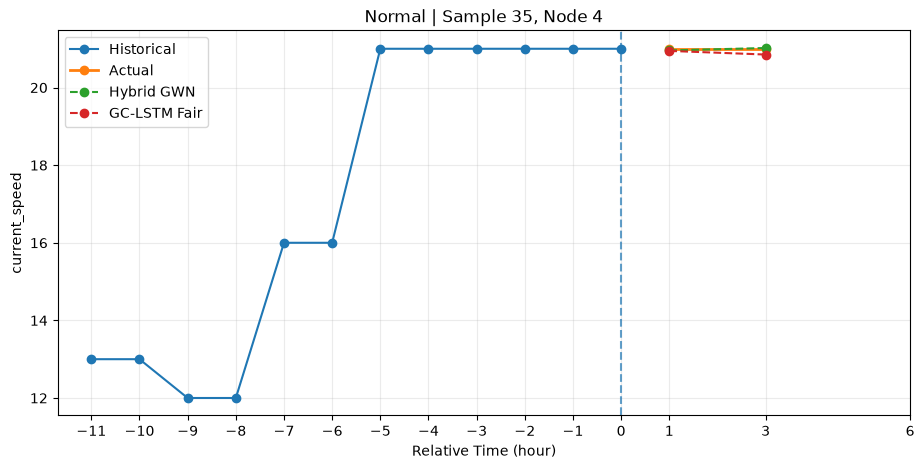

,horizon,actual,hybrid_pred,gclstm_pred,hybrid_abs_error,gclstm_abs_error
0,t+1,21.0,20.956600,20.945299,0.0434,0.0547
1,t+3,21.0,21.019699,20.851000,0.0197,0.1490


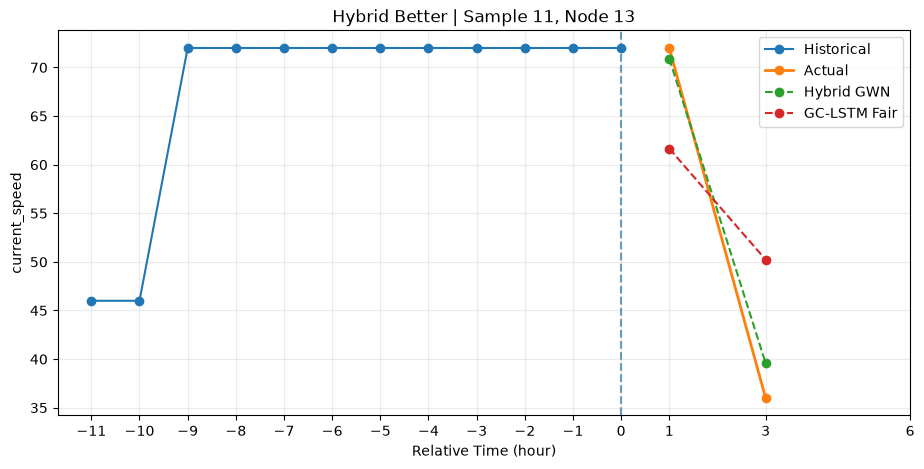

,horizon,actual,hybrid_pred,gclstm_pred,hybrid_abs_error,gclstm_abs_error
0,t+1,72.0,70.912498,61.658600,1.0875,10.3414
1,t+3,36.0,39.578098,50.230999,3.5781,14.2310


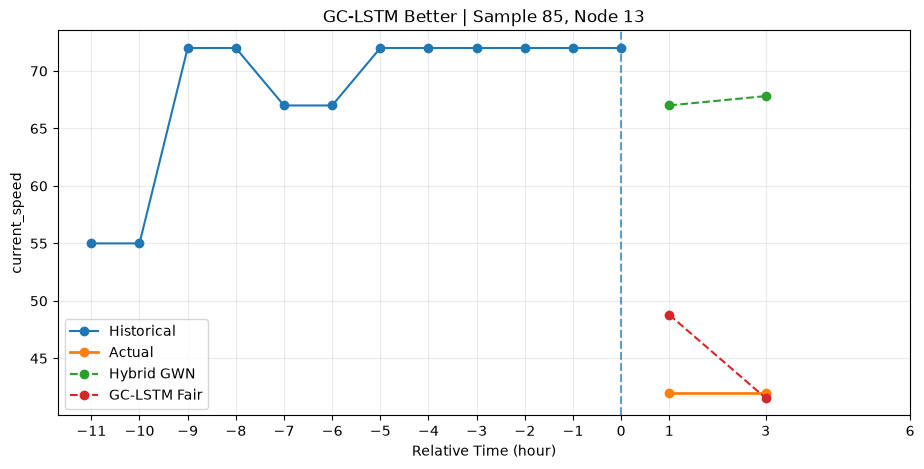

,horizon,actual,hybrid_pred,gclstm_pred,hybrid_abs_error,gclstm_abs_error
0,t+1,42.0,67.005402,48.7901,25.0054,6.7901
1,t+3,42.0,67.815300,41.5490,25.8153,0.4510


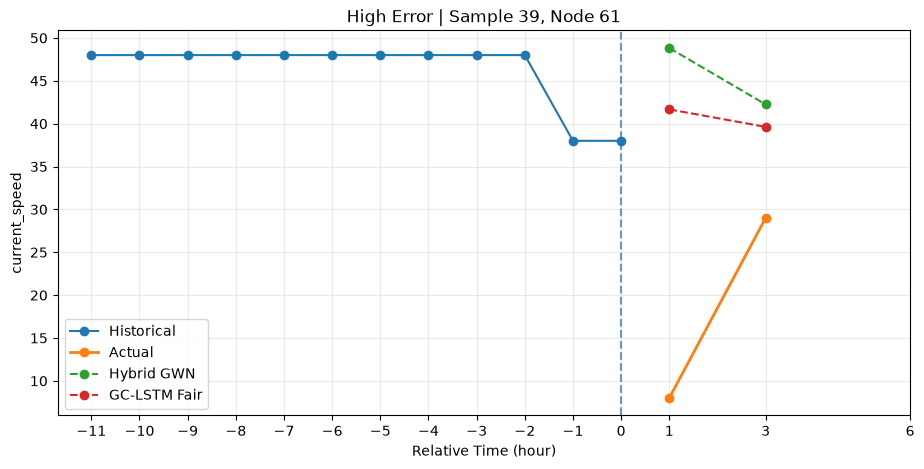

,horizon,actual,hybrid_pred,gclstm_pred,hybrid_abs_error,gclstm_abs_error
0,t+1,8.0,48.827999,41.664398,40.827999,33.664398
1,t+3,29.0,42.249802,39.627602,13.249800,10.627600


In [10]:
for _, row in selected_cases.iterrows():
    plot_demo_case(sample_idx=row["sample_idx"], node_idx=row["node_idx"], case_name=row["case"])

## Add Actual Prediction Time

Untuk mempermudah interpretasi demo, indeks sample dikonversi menjadi waktu prediksi aktual berdasarkan `target_times` pada test set.

In [11]:
# ============================================================
# LOAD TARGET TIMES
# ============================================================

target_times = test_data["target_times"]

print("target_times shape:", target_times.shape)
print("dtype:", target_times.dtype)

print("\nFirst sample:")
print(target_times[0])

print("\nSelected demo cases:")

for _, row in selected_cases.iterrows():
    sample_idx = int(row["sample_idx"])
    node_idx = int(row["node_idx"])

    print(f"\n{row['case']} | Sample {sample_idx} | Node {node_idx}")

    print(target_times[sample_idx])

target_times shape: (93, 3)
dtype: object

First sample:
[Timestamp('2026-09-07 11:00:00+0000', tz='UTC')
 Timestamp('2026-09-07 13:00:00+0000', tz='UTC')
 Timestamp('2026-09-07 16:00:00+0000', tz='UTC')]

Selected demo cases:

Normal | Sample 35 | Node 4
[Timestamp('2026-09-08 22:00:00+0000', tz='UTC')
 Timestamp('2026-09-09 00:00:00+0000', tz='UTC')
 Timestamp('2026-09-09 03:00:00+0000', tz='UTC')]

Hybrid Better | Sample 11 | Node 13
[Timestamp('2026-09-07 22:00:00+0000', tz='UTC')
 Timestamp('2026-09-08 00:00:00+0000', tz='UTC')
 Timestamp('2026-09-08 03:00:00+0000', tz='UTC')]

GC-LSTM Better | Sample 85 | Node 13
[Timestamp('2026-09-11 00:00:00+0000', tz='UTC')
 Timestamp('2026-09-11 02:00:00+0000', tz='UTC')
 Timestamp('2026-09-11 05:00:00+0000', tz='UTC')]

High Error | Sample 39 | Node 61
[Timestamp('2026-09-09 02:00:00+0000', tz='UTC')
 Timestamp('2026-09-09 04:00:00+0000', tz='UTC')
 Timestamp('2026-09-09 07:00:00+0000', tz='UTC')]


## Convert Prediction Time to WIB

Waktu pada dataset disimpan dalam UTC. Untuk keperluan interpretasi dan presentasi, waktu dikonversi ke WIB (UTC+7).

In [12]:
# ============================================================
# CONVERT TARGET TIMES UTC -> WIB
# ============================================================


def to_wib(timestamp):
    return pd.Timestamp(timestamp).tz_convert("Asia/Jakarta")


for _, row in selected_cases.iterrows():
    sample_idx = int(row["sample_idx"])
    node_idx = int(row["node_idx"])

    times_wib = [to_wib(t) for t in target_times[sample_idx]]

    print(f"\n{row['case']} | Sample {sample_idx} | Node {node_idx}")

    print("t+1:", times_wib[0].strftime("%d %b %Y %H:%M WIB"))

    print("t+3:", times_wib[1].strftime("%d %b %Y %H:%M WIB"))

    print("t+6:", times_wib[2].strftime("%d %b %Y %H:%M WIB"))


Normal | Sample 35 | Node 4
t+1: 09 Sep 2026 05:00 WIB
t+3: 09 Sep 2026 07:00 WIB
t+6: 09 Sep 2026 10:00 WIB

Hybrid Better | Sample 11 | Node 13
t+1: 08 Sep 2026 05:00 WIB
t+3: 08 Sep 2026 07:00 WIB
t+6: 08 Sep 2026 10:00 WIB

GC-LSTM Better | Sample 85 | Node 13
t+1: 11 Sep 2026 07:00 WIB
t+3: 11 Sep 2026 09:00 WIB
t+6: 11 Sep 2026 12:00 WIB

High Error | Sample 39 | Node 61
t+1: 09 Sep 2026 09:00 WIB
t+3: 09 Sep 2026 11:00 WIB
t+6: 09 Sep 2026 14:00 WIB


## Add Corridor Names to Demo

Node index dipetakan ke nama corridor menggunakan `final_64_corridors.csv`.

Dengan ini, visualisasi demo tidak hanya menampilkan indeks node, tetapi juga nama corridor yang lebih mudah diinterpretasikan.

In [13]:
# ============================================================
# LOAD CORRIDOR MAPPING
# ============================================================

CORRIDOR_PATH = ROOT / "data" / "final_64" / "final_64_corridors.csv"

corridor_df = pd.read_csv(CORRIDOR_PATH)

corridor_map = dict(zip(corridor_df["node_index"], corridor_df["corridor_file"]))


def clean_corridor_name(filename):
    return filename.replace("tt_", "").replace(".csv", "").replace("_", " ").title()


print("Node 4  :", clean_corridor_name(corridor_map[4]))
print("Node 13 :", clean_corridor_name(corridor_map[13]))
print("Node 61 :", clean_corridor_name(corridor_map[61]))

Node 4  : Kuningan
Node 13 : Tbsimatupang
Node 61 : Supomo


In [14]:
def plot_demo_case(sample_idx, node_idx, case_name):
    sample_idx = int(sample_idx)
    node_idx = int(node_idx)

    corridor_name = get_corridor_name(node_idx)

    # historical
    history_std = X_test[sample_idx, :, node_idx, 0]

    history_real = inverse_scale(history_std)

    actual = y_true_real[sample_idx, :, node_idx]

    hybrid = hybrid_pred[sample_idx, :, node_idx]

    gclstm = gclstm_pred[sample_idx, :, node_idx]

    valid = mask_test[sample_idx, :, node_idx] == 1

    # target times WIB
    times_wib = [to_wib(t) for t in target_times[sample_idx]]

    valid_times = [times_wib[i] for i in range(3) if valid[i]]

    # --------------------------------------------------------
    # PLOT
    # --------------------------------------------------------

    plt.figure(figsize=(11, 5))

    plt.plot(HIST_X, history_real, marker="o", label="Historical")

    plt.axvline(x=0, linestyle="--", alpha=0.7)

    actual_x = [HORIZON_STEPS[i] for i in range(3) if valid[i]]

    actual_y = [actual[i] for i in range(3) if valid[i]]

    hybrid_y = [hybrid[i] for i in range(3) if valid[i]]

    gclstm_y = [gclstm[i] for i in range(3) if valid[i]]

    plt.plot(actual_x, actual_y, marker="o", linewidth=2, label="Actual")

    plt.plot(actual_x, hybrid_y, marker="o", linestyle="--", label="Hybrid GWN")

    plt.plot(actual_x, gclstm_y, marker="o", linestyle="--", label="GC-LSTM Fair")

    start_time = valid_times[0].strftime("%d %b %Y %H:%M")

    end_time = valid_times[-1].strftime("%H:%M WIB")

    plt.title(f"{case_name} | {corridor_name}\n{start_time} - {end_time}")

    plt.xlabel("Relative Time (hour)")

    plt.ylabel("Current Speed")

    plt.xticks(HIST_X + HORIZON_STEPS)

    plt.grid(alpha=0.25)

    plt.legend()

    plt.show()

    # --------------------------------------------------------
    # DETAIL TABLE
    # --------------------------------------------------------

    rows = []

    for i, h in enumerate(HORIZON_STEPS):
        if valid[i]:
            rows.append(
                {
                    "horizon": f"t+{h}",
                    "time_wib": times_wib[i].strftime("%d %b %Y %H:%M"),
                    "actual": actual[i],
                    "hybrid_pred": hybrid[i],
                    "gclstm_pred": gclstm[i],
                    "hybrid_abs_error": abs(actual[i] - hybrid[i]),
                    "gclstm_abs_error": abs(actual[i] - gclstm[i]),
                }
            )

    detail_df = pd.DataFrame(rows)

    display(detail_df.round(4))

In [16]:
# ============================================================
# CORRIDOR NAME HELPERS
# ============================================================

CORRIDOR_PATH = ROOT / "data" / "final_64" / "final_64_corridors.csv"

corridor_df = pd.read_csv(CORRIDOR_PATH)

corridor_map = dict(zip(corridor_df["node_index"], corridor_df["corridor_file"]))


def clean_corridor_name(filename):
    return filename.replace("tt_", "").replace(".csv", "").replace("_", " ").title()


CORRIDOR_ALIASES = {
    "Tbsimatupang": "TB Simatupang",
    "Kuningan": "Kuningan",
    "Supomo": "Supomo",
}


def get_corridor_name(node_idx):
    raw_name = clean_corridor_name(corridor_map[int(node_idx)])

    return CORRIDOR_ALIASES.get(raw_name, raw_name)


print(get_corridor_name(4))
print(get_corridor_name(13))
print(get_corridor_name(61))

Kuningan
TB Simatupang
Supomo


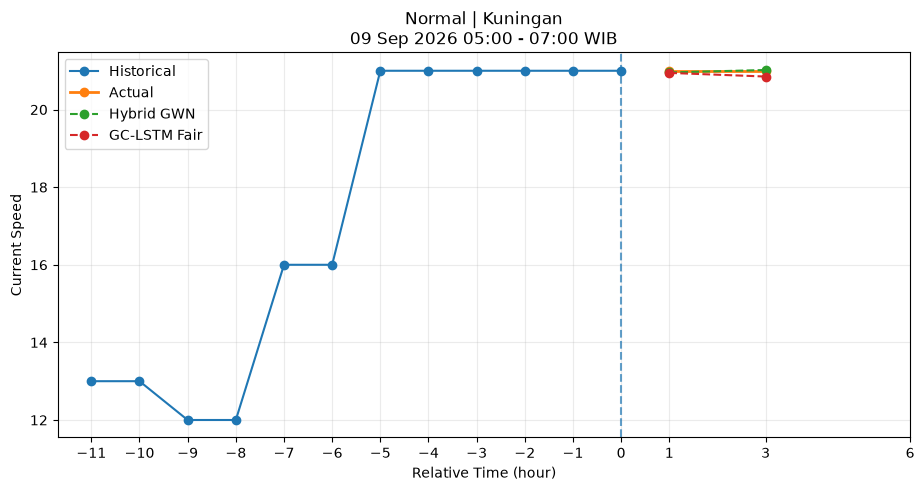

,horizon,time_wib,actual,hybrid_pred,gclstm_pred,hybrid_abs_error,gclstm_abs_error
0,t+1,09 Sep 2026 05:00,21.0,20.956600,20.945299,0.0434,0.0547
1,t+3,09 Sep 2026 07:00,21.0,21.019699,20.851000,0.0197,0.1490


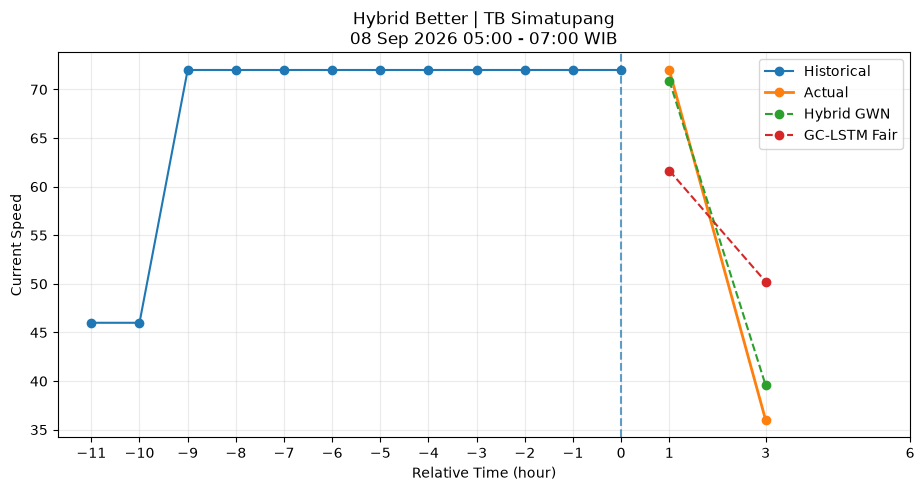

,horizon,time_wib,actual,hybrid_pred,gclstm_pred,hybrid_abs_error,gclstm_abs_error
0,t+1,08 Sep 2026 05:00,72.0,70.912498,61.658600,1.0875,10.3414
1,t+3,08 Sep 2026 07:00,36.0,39.578098,50.230999,3.5781,14.2310


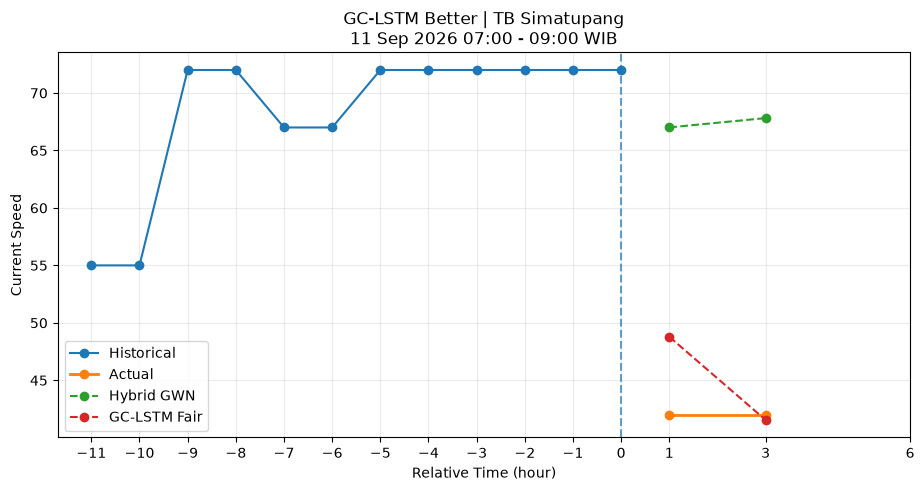

,horizon,time_wib,actual,hybrid_pred,gclstm_pred,hybrid_abs_error,gclstm_abs_error
0,t+1,11 Sep 2026 07:00,42.0,67.005402,48.7901,25.0054,6.7901
1,t+3,11 Sep 2026 09:00,42.0,67.815300,41.5490,25.8153,0.4510


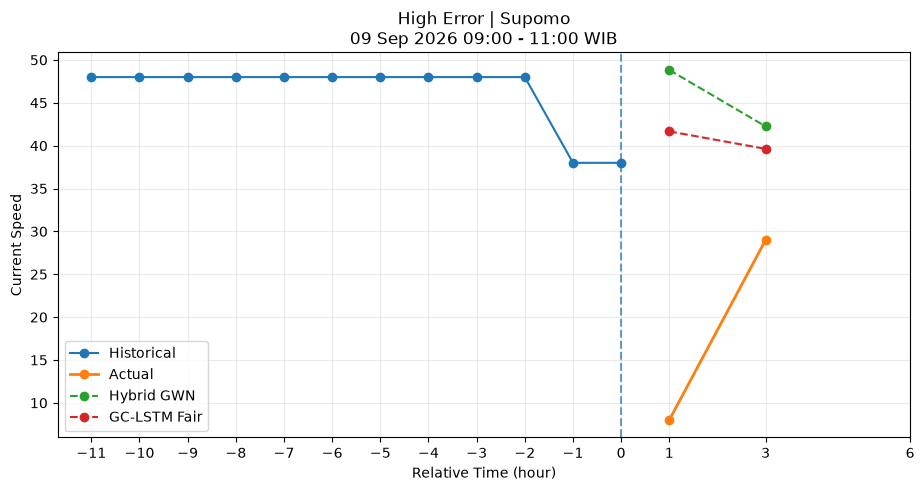

,horizon,time_wib,actual,hybrid_pred,gclstm_pred,hybrid_abs_error,gclstm_abs_error
0,t+1,09 Sep 2026 09:00,8.0,48.827999,41.664398,40.827999,33.664398
1,t+3,09 Sep 2026 11:00,29.0,42.249802,39.627602,13.249800,10.627600


In [17]:
for _, row in selected_cases.iterrows():
    plot_demo_case(sample_idx=row["sample_idx"], node_idx=row["node_idx"], case_name=row["case"])

In [18]:
# ============================================================
# BETTER REPRESENTATIVE DEMO CASES
# ============================================================

pair_pool = case_df[case_df["valid_horizons"] == 2].copy()

pair_pool["mean_error_both"] = (pair_pool["hybrid_mae"] + pair_pool["gclstm_mae"]) / 2

# ------------------------------------------------------------
# 1. NORMAL CASE
# pilih error rendah, tapi bukan kasus super-perfect 0.03
# ------------------------------------------------------------

low_q = pair_pool["mean_error_both"].quantile(0.20)

normal_candidates = pair_pool[pair_pool["mean_error_both"] >= low_q].copy()

normal_case = normal_candidates.sort_values("mean_error_both").iloc[0]

# ------------------------------------------------------------
# Hindari extreme outlier untuk model-better cases
# ------------------------------------------------------------

error_limit = pair_pool["mean_error_both"].quantile(0.75)

reasonable_pool = pair_pool[pair_pool["mean_error_both"] <= error_limit].copy()

# ------------------------------------------------------------
# 2. HYBRID BETTER
# ------------------------------------------------------------

hybrid_candidates = reasonable_pool[reasonable_pool["difference"] > 0].copy()

hybrid_better_case = hybrid_candidates.sort_values("difference", ascending=False).iloc[0]

# ------------------------------------------------------------
# 3. GC-LSTM BETTER
# ------------------------------------------------------------

gclstm_candidates = reasonable_pool[reasonable_pool["difference"] < 0].copy()

gclstm_better_case = gclstm_candidates.sort_values("difference").iloc[0]

selected_cases_clean = pd.DataFrame(
    [
        {"case": "Normal", **normal_case.to_dict()},
        {"case": "Hybrid Better", **hybrid_better_case.to_dict()},
        {"case": "GC-LSTM Better", **gclstm_better_case.to_dict()},
    ]
)

display(
    selected_cases_clean[
        [
            "case",
            "sample_idx",
            "node_idx",
            "valid_horizons",
            "hybrid_mae",
            "gclstm_mae",
            "difference",
        ]
    ]
)

,case,sample_idx,node_idx,valid_horizons,hybrid_mae,gclstm_mae,difference
0,Normal,29.0,51.0,2.0,1.065742,0.140196,-0.925547
1,Hybrid Better,63.0,0.0,2.0,0.304784,4.146356,3.841572
2,GC-LSTM Better,7.0,59.0,2.0,5.110971,0.649284,-4.461687


In [19]:
# ============================================================
# REPRESENTATIVE T+6 CASE
# ============================================================

t6_rows = []

for sample_idx in range(len(X_test)):
    for node_idx in range(NUM_NODES):
        # hanya target t+6 yang valid
        if mask_test[sample_idx, 2, node_idx] != 1:
            continue

        actual = y_true_real[sample_idx, 2, node_idx]

        hybrid = hybrid_pred[sample_idx, 2, node_idx]

        gclstm = gclstm_pred[sample_idx, 2, node_idx]

        hybrid_error = abs(actual - hybrid)

        gclstm_error = abs(actual - gclstm)

        t6_rows.append(
            {
                "sample_idx": sample_idx,
                "node_idx": node_idx,
                "actual": actual,
                "hybrid_pred": hybrid,
                "gclstm_pred": gclstm,
                "hybrid_error": hybrid_error,
                "gclstm_error": gclstm_error,
                "mean_error": (hybrid_error + gclstm_error) / 2,
            }
        )

t6_df = pd.DataFrame(t6_rows)

# pilih sekitar median supaya representatif,
# bukan best case dan bukan worst case
median_t6 = t6_df["mean_error"].median()

t6_df["distance_to_median"] = abs(t6_df["mean_error"] - median_t6)

t6_case = t6_df.sort_values("distance_to_median").iloc[0]

print("=== REPRESENTATIVE T+6 CASE ===")
display(pd.DataFrame([t6_case]).round(4))

=== REPRESENTATIVE T+6 CASE ===


,sample_idx,node_idx,actual,hybrid_pred,gclstm_pred,hybrid_error,gclstm_error,mean_error,distance_to_median
1614,50.0,14.0,39.0,41.9411,38.8903,2.9411,0.1097,1.5254,0.0009


In [20]:
# ============================================================
# FIND CORRIDORS WITH VALID DATA FOR ALL HORIZONS
# across different samples
# ============================================================

coverage_rows = []

for node_idx in range(NUM_NODES):
    counts = []

    for h_idx in range(3):
        count_valid = int(mask_test[:, h_idx, node_idx].sum())
        counts.append(count_valid)

    coverage_rows.append(
        {
            "node_idx": node_idx,
            "corridor": get_corridor_name(node_idx),
            "valid_t1": counts[0],
            "valid_t3": counts[1],
            "valid_t6": counts[2],
            "total_valid": sum(counts),
        }
    )

coverage_df = pd.DataFrame(coverage_rows)

coverage_all = coverage_df[
    (coverage_df["valid_t1"] > 0) & (coverage_df["valid_t3"] > 0) & (coverage_df["valid_t6"] > 0)
].copy()

coverage_all = coverage_all.sort_values("total_valid", ascending=False)

display(coverage_all.head(10))

,node_idx,corridor,valid_t1,valid_t3,valid_t6,total_valid
0,0,Cawang,46,46,47,139
1,1,Gatsu,46,46,47,139
34,34,Gunungsahari,46,46,47,139
35,35,Hayamwuruk,46,46,47,139
36,36,Jatinegara,46,46,47,139
37,37,Jorr West,46,46,47,139
38,38,Kapukmuara,46,46,47,139
39,39,Karawaci,46,46,47,139
40,40,Kedoya,46,46,47,139
41,41,Kemang,46,46,47,139


## Combined t+1, t+3, t+6 Demo

Karena mask pada Final64 tidak menyediakan t+1, t+3, dan t+6 secara bersamaan pada sample yang sama, demo menggunakan corridor yang sama dengan sample valid yang berbeda untuk setiap horizon.

Untuk menghindari pemilihan best-case atau worst-case, pada setiap horizon dipilih sample dengan error gabungan Hybrid GWN dan GC-LSTM yang paling dekat dengan median.

In [21]:
# ============================================================
# SELECT REPRESENTATIVE CASE FOR EACH HORIZON
# SAME CORRIDOR
# ============================================================

DEMO_NODE = 0  # Cawang
DEMO_CORRIDOR = get_corridor_name(DEMO_NODE)

HORIZON_LABELS = ["t+1", "t+3", "t+6"]

representative_rows = []

for h_idx, h_label in enumerate(HORIZON_LABELS):
    rows = []

    for sample_idx in range(len(X_test)):
        if mask_test[sample_idx, h_idx, DEMO_NODE] != 1:
            continue

        actual = y_true_real[sample_idx, h_idx, DEMO_NODE]

        hybrid = hybrid_pred[sample_idx, h_idx, DEMO_NODE]

        gclstm = gclstm_pred[sample_idx, h_idx, DEMO_NODE]

        hybrid_error = abs(actual - hybrid)
        gclstm_error = abs(actual - gclstm)

        mean_error = (hybrid_error + gclstm_error) / 2

        rows.append(
            {
                "sample_idx": sample_idx,
                "horizon_idx": h_idx,
                "horizon": h_label,
                "actual": actual,
                "hybrid_pred": hybrid,
                "gclstm_pred": gclstm,
                "hybrid_error": hybrid_error,
                "gclstm_error": gclstm_error,
                "mean_error": mean_error,
            }
        )

    horizon_df = pd.DataFrame(rows)

    median_error = horizon_df["mean_error"].median()

    horizon_df["distance_to_median"] = abs(horizon_df["mean_error"] - median_error)

    chosen = horizon_df.sort_values("distance_to_median").iloc[0].to_dict()

    representative_rows.append(chosen)

representative_demo = pd.DataFrame(representative_rows)

representative_demo["corridor"] = DEMO_CORRIDOR

display(
    representative_demo[
        [
            "corridor",
            "horizon",
            "sample_idx",
            "actual",
            "hybrid_pred",
            "gclstm_pred",
            "hybrid_error",
            "gclstm_error",
        ]
    ].round(4)
)

,corridor,horizon,sample_idx,actual,hybrid_pred,gclstm_pred,hybrid_error,gclstm_error
0,Cawang,t+1,15,20.0,17.6550,25.5867,2.3450,5.5867
1,Cawang,t+3,49,43.0,38.8358,40.5138,4.1642,2.4862
2,Cawang,t+6,14,31.0,26.7677,29.4441,4.2323,1.5559


## Final Demo Comparison: Hybrid Graph WaveNet vs GC-LSTM Fair

Demo ini menampilkan perbandingan prediksi pada satu corridor yang sama, yaitu **Cawang**, untuk horizon **t+1, t+3, dan t+6**.

Karena target valid pada Final64 tidak selalu tersedia lengkap pada sample yang sama, masing-masing horizon menggunakan sample valid yang representatif:
- t+1 → sample 15
- t+3 → sample 49
- t+6 → sample 14

Tujuannya agar ketiga horizon tetap dapat didemonstrasikan secara jelas pada corridor yang sama.

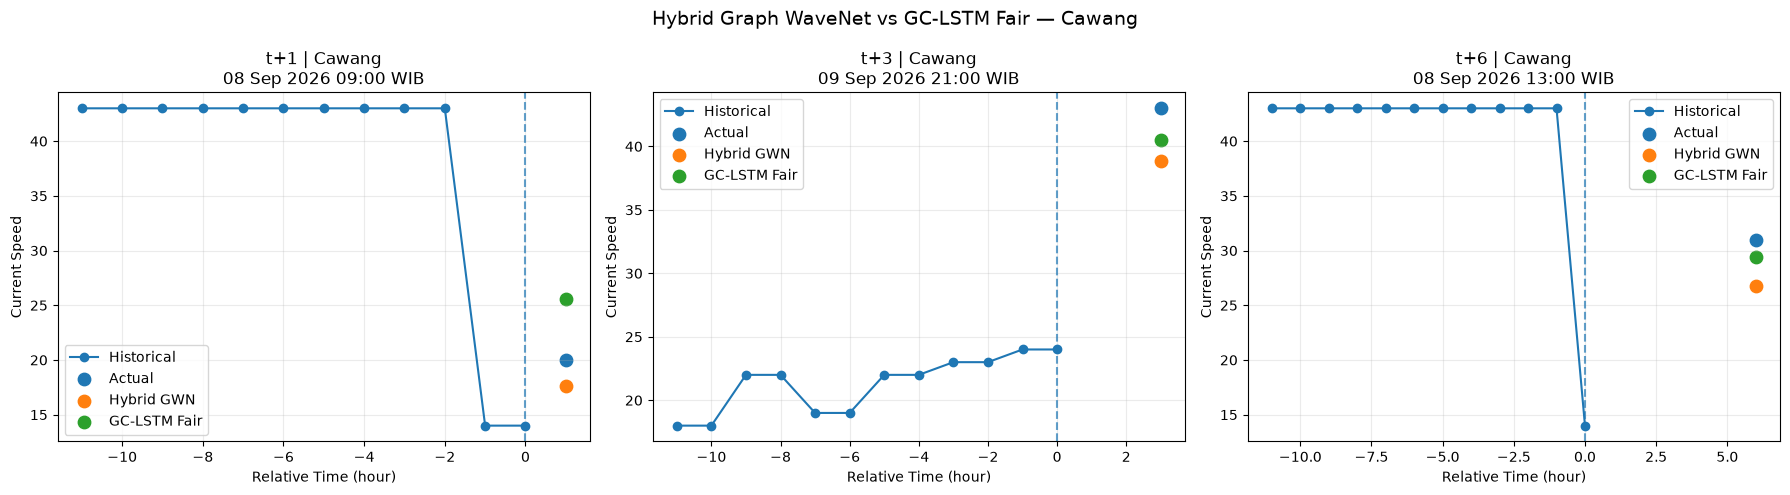


=== FINAL DEMO SUMMARY ===


,corridor,horizon,sample_idx,time_wib,actual,hybrid_pred,gclstm_pred,hybrid_abs_error,gclstm_abs_error
0,Cawang,t+1,15,08 Sep 2026 09:00 WIB,20.0,17.6550,25.5867,2.3450,5.5867
1,Cawang,t+3,49,09 Sep 2026 21:00 WIB,43.0,38.8358,40.5138,4.1642,2.4862
2,Cawang,t+6,14,08 Sep 2026 13:00 WIB,31.0,26.7677,29.4441,4.2323,1.5559



=== SAVED OUTPUTS ===
Figure : /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/outputs/final_64/demo_compare/gwn_vs_gclstm_cawang_t1_t3_t6.png
CSV    : /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/outputs/final_64/demo_compare/gwn_vs_gclstm_cawang_t1_t3_t6.csv
Figure exists: True
CSV exists   : True


In [23]:
# ============================================================
# FINAL FIXED DEMO
# HYBRID GWN vs GC-LSTM FAIR
# CAWANG: t+1, t+3, t+6
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# OUTPUT DIR
# ------------------------------------------------------------

DEMO_DIR = ROOT / "outputs" / "final_64" / "demo_compare"

DEMO_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# DEMO CONFIG
# ------------------------------------------------------------

DEMO_NODE = 0
DEMO_CORRIDOR = get_corridor_name(DEMO_NODE)

demo_cases = [
    {"horizon": "t+1", "h_idx": 0, "sample_idx": 15, "future_x": 1},
    {"horizon": "t+3", "h_idx": 1, "sample_idx": 49, "future_x": 3},
    {"horizon": "t+6", "h_idx": 2, "sample_idx": 14, "future_x": 6},
]

# ------------------------------------------------------------
# BUILD SUMMARY
# ------------------------------------------------------------

summary_rows = []

for case in demo_cases:
    sample_idx = case["sample_idx"]
    h_idx = case["h_idx"]

    actual = float(y_true_real[sample_idx, h_idx, DEMO_NODE])

    hybrid_val = float(hybrid_pred[sample_idx, h_idx, DEMO_NODE])

    gclstm_val = float(gclstm_pred[sample_idx, h_idx, DEMO_NODE])

    target_time = pd.Timestamp(target_times[sample_idx, h_idx]).tz_convert("Asia/Jakarta")

    hybrid_error = abs(actual - hybrid_val)

    gclstm_error = abs(actual - gclstm_val)

    summary_rows.append(
        {
            "corridor": DEMO_CORRIDOR,
            "horizon": case["horizon"],
            "sample_idx": sample_idx,
            "time_wib": target_time.strftime("%d %b %Y %H:%M WIB"),
            "actual": actual,
            "hybrid_pred": hybrid_val,
            "gclstm_pred": gclstm_val,
            "hybrid_abs_error": hybrid_error,
            "gclstm_abs_error": gclstm_error,
        }
    )

demo_summary = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

history_x = np.arange(-11, 1)

for ax, case, summary in zip(axes, demo_cases, summary_rows):
    sample_idx = case["sample_idx"]
    h_idx = case["h_idx"]
    future_x = case["future_x"]

    # historical input -> real scale
    history_real = inverse_scale(X_test[sample_idx, :, DEMO_NODE, 0])

    actual = summary["actual"]
    hybrid_val = summary["hybrid_pred"]
    gclstm_val = summary["gclstm_pred"]

    # historical
    ax.plot(history_x, history_real, marker="o", label="Historical")

    # boundary H0
    ax.axvline(x=0, linestyle="--", alpha=0.7)

    # forecast point
    ax.scatter([future_x], [actual], s=80, label="Actual")

    ax.scatter([future_x], [hybrid_val], s=80, label="Hybrid GWN")

    ax.scatter([future_x], [gclstm_val], s=80, label="GC-LSTM Fair")

    ax.set_title(f"{case['horizon']} | {DEMO_CORRIDOR}\n{summary['time_wib']}")

    ax.set_xlabel("Relative Time (hour)")

    ax.set_ylabel("Current Speed")

    ax.grid(alpha=0.25)

    ax.legend()

fig.suptitle("Hybrid Graph WaveNet vs GC-LSTM Fair — Cawang", fontsize=14)

plt.tight_layout()

# ------------------------------------------------------------
# SAVE FIGURE
# ------------------------------------------------------------

FIG_PATH = DEMO_DIR / "gwn_vs_gclstm_cawang_t1_t3_t6.png"

fig.savefig(FIG_PATH, dpi=200, bbox_inches="tight")

plt.show()

# ------------------------------------------------------------
# SAVE CSV
# ------------------------------------------------------------

CSV_PATH = DEMO_DIR / "gwn_vs_gclstm_cawang_t1_t3_t6.csv"

demo_summary.to_csv(CSV_PATH, index=False)

print("\n=== FINAL DEMO SUMMARY ===")
display(demo_summary.round(4))

print("\n=== SAVED OUTPUTS ===")
print("Figure :", FIG_PATH)
print("CSV    :", CSV_PATH)
print("Figure exists:", FIG_PATH.exists())
print("CSV exists   :", CSV_PATH.exists())